In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay,
)

In [3]:
train = pd.read_csv("C:\\imp stuff\\credit car fraou\\data\\train.csv")

# Clues = every column except Class. Answer = Class.
X_train = train.drop(columns=["Class"])
y_train = train["Class"]

print("Training rows:", len(X_train))
print("Frauds:", y_train.sum(), f"({y_train.mean() * 100:.3f}%)")

Training rows: 226980
Frauds: 378 (0.167%)


In [4]:
# Create and "train" the dumb model. It just learns which answer is most common.
dumb = DummyClassifier(strategy="most_frequent")
dumb.fit(X_train, y_train)

# Predict on the training data (every prediction will be 0 = legit)
dumb_pred = dumb.predict(X_train)

print(f"Accuracy: {accuracy_score(y_train, dumb_pred) * 100:.2f}%")
print(f"Recall:   {recall_score(y_train, dumb_pred) * 100:.2f}%   <- catches no fraud at all")

Accuracy: 99.83%
Recall:   0.00%   <- catches no fraud at all


In [5]:

# random_state keeps results repeatable.
model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

# Cut the training data into 5 chunks, keeping the fraud percentage equal in each
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For each row, get the model's predicted probability of fraud, from a model that never saw it.
# method="predict_proba" returns two columns: [prob legit, prob fraud]
# [:, 1] keeps just the second column (the fraud probability) for every row.
fraud_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

print("Done. Example fraud probabilities for the first 5 rows:", fraud_prob[:5].round(4))

Done. Example fraud probabilities for the first 5 rows: [0.0031 0.001  0.0426 0.4969 0.0075]


In [6]:
threshold = 0.5

# (fraud_prob >= threshold) is True/False for each row; .astype(int) turns that into 1/0
pred = (fraud_prob >= threshold).astype(int)

print(f"Flagged as fraud: {pred.sum():,} transactions out of {len(pred):,}")
print(f"Real frauds:      {y_train.sum():,}")

Flagged as fraud: 5,804 transactions out of 226,980
Real frauds:      378


In [7]:
# Compare the model's decisions (pred) with the truth (y_train)
precision = precision_score(y_train, pred)
recall = recall_score(y_train, pred)
f1 = f1_score(y_train, pred)

# PR-AUC uses the raw probabilities, so it covers every threshold
pr_auc = average_precision_score(y_train, fraud_prob)

print(f"Precision: {precision:.3f}   (of alerts raised, share that were real fraud)")
print(f"Recall:    {recall:.3f}   (of real fraud, share we caught)")
print(f"F1:        {f1:.3f}")
print(f"PR-AUC:    {pr_auc:.3f}   (random guessing would be about {y_train.mean():.3f})")

Precision: 0.060   (of alerts raised, share that were real fraud)
Recall:    0.918   (of real fraud, share we caught)
F1:        0.112
PR-AUC:    0.737   (random guessing would be about 0.002)


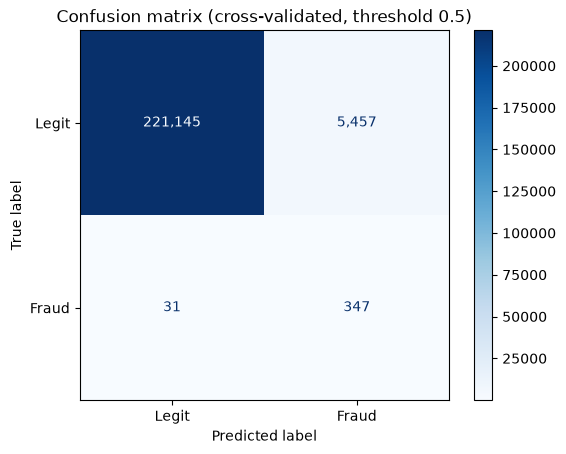

Frauds caught: 347   Frauds missed: 31
False alarms:  5,457 legit transactions wrongly flagged


In [8]:
# Draw the confusion matrix straight from the truth and the predictions
ConfusionMatrixDisplay.from_predictions(
    y_train, pred,
    display_labels=["Legit", "Fraud"],
    cmap="Blues",
    values_format=",",      # show numbers like 12,345 rather than 1.2e+04
)
plt.title("Confusion matrix (cross-validated, threshold 0.5)")
plt.grid(False)
plt.show()

# Pull out the four numbers: ravel() flattens the 2x2 grid into a single row
tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
print(f"Frauds caught: {tp}   Frauds missed: {fn}")
print(f"False alarms:  {fp:,} legit transactions wrongly flagged")

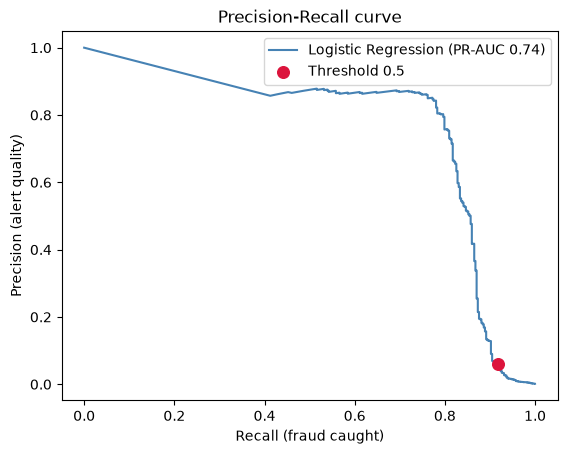

In [9]:
# precision_recall_curve returns precision and recall for many thresholds
prec_curve, rec_curve, thresholds = precision_recall_curve(y_train, fraud_prob)

plt.plot(rec_curve, prec_curve, color="steelblue", label=f"Logistic Regression (PR-AUC {pr_auc:.2f})")

# Mark where our chosen threshold (0.5) sits on the curve
plt.scatter([recall], [precision], color="crimson", s=70, zorder=5, label="Threshold 0.5")


plt.xlabel("Recall (fraud caught)")
plt.ylabel("Precision (alert quality)")
plt.title("Precision-Recall curve")
plt.legend()
plt.show()